# Chapter 4 - Bounds Estimation

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#4.2.2-Simulation-of-Impossible-Data" data-toc-modified-id="4.2.2-Simulation-of-Impossible-Data-1">4.2.2 Simulation of Impossible Data</a></span></li><li><span><a href="#4.2.3-Distribution-of-the-Treatment-Effect" data-toc-modified-id="4.2.3-Distribution-of-the-Treatment-Effect-2">4.2.3 Distribution of the Treatment Effect</a></span></li><li><span><a href="#4.3.1-ATE-and-Its-Derivation" data-toc-modified-id="4.3.1-ATE-and-Its-Derivation-3">4.3.1 ATE and Its Derivation</a></span></li><li><span><a href="#4.3.4-ATE-and-Simulated-Data" data-toc-modified-id="4.3.4-ATE-and-Simulated-Data-4">4.3.4 ATE and Simulated Data</a></span></li><li><span><a href="#4.4.2-Kolmogorov-Bounds-in-Python" data-toc-modified-id="4.4.2-Kolmogorov-Bounds-in-Python-5">4.4.2 Kolmogorov Bounds in Python</a></span></li><li><span><a href="#4.5.1-Field-Experiment-Data" data-toc-modified-id="4.5.1-Field-Experiment-Data-6">4.5.1 Field Experiment Data</a></span></li><li><span><a href="#4.5.2-Bounds-on-the-Distribution-of-Balance-Changes" data-toc-modified-id="4.5.2-Bounds-on-the-Distribution-of-Balance-Changes-7">4.5.2 Bounds on the Distribution of Balance Changes</a></span></li><li><span><a href="#4.6.2-Simulation-of-Manski-Bounds" data-toc-modified-id="4.6.2-Simulation-of-Manski-Bounds-8">4.6.2 Simulation of Manski Bounds</a></span></li><li><span><a href="#4.6.5-Natural-Bounds-with-Simulated-Data" data-toc-modified-id="4.6.5-Natural-Bounds-with-Simulated-Data-9">4.6.5 Natural Bounds with Simulated Data</a></span></li><li><span><a href="#4.6.8-Exogenous-Variation-in-Simulated-Data" data-toc-modified-id="4.6.8-Exogenous-Variation-in-Simulated-Data-10">4.6.8 Exogenous Variation in Simulated Data</a></span></li><li><span><a href="#4.6.10-Bounds-with-Monotonicity-in-the-Simulated-Data" data-toc-modified-id="4.6.10-Bounds-with-Monotonicity-in-the-Simulated-Data-11">4.6.10 Bounds with Monotonicity in the Simulated Data</a></span></li><li><span><a href="#4.7.1-Crime-Data" data-toc-modified-id="4.7.1-Crime-Data-12">4.7.1 Crime Data</a></span></li><li><span><a href="#4.7.2-ATE-of-RTC-Laws-under-Unconfoundedness" data-toc-modified-id="4.7.2-ATE-of-RTC-Laws-under-Unconfoundedness-13">4.7.2 ATE of RTC Laws under Unconfoundedness</a></span></li><li><span><a href="#4.7.3-Natural-Bounds-on-ATE-of-RTC-Laws" data-toc-modified-id="4.7.3-Natural-Bounds-on-ATE-of-RTC-Laws-14">4.7.3 Natural Bounds on ATE of RTC Laws</a></span></li><li><span><a href="#4.7.4-Bounds-on-ATE-of-RTC-Laws-with-Exogenous-Variation" data-toc-modified-id="4.7.4-Bounds-on-ATE-of-RTC-Laws-with-Exogenous-Variation-15">4.7.4 Bounds on ATE of RTC Laws with Exogenous Variation</a></span></li><li><span><a href="#4.7.5-Bounds-on-ATE-of-RTC-Laws-with-Monotonicity" data-toc-modified-id="4.7.5-Bounds-on-ATE-of-RTC-Laws-with-Monotonicity-16">4.7.5 Bounds on ATE of RTC Laws with Monotonicity</a></span></li></ul></div>

## 4.2.2 Simulation of Impossible Data

In [1]:
# as in the previous chapters, we use numpy
import numpy as np

In [2]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 200
a = 2

# this creates variation in the slope with an average
# effect of 2.
# loc is the mean and scale is the standard deviation (sd in R)
b = np.random.normal(loc=2, scale=3, size=N)

x0 = np.zeros(N) # creates a vector of zeros
x1 = np.ones(N) # and a vector of ones
u = np.random.normal(size=N)

# y is a matrix, [a + u, a + b + u]
# first column: the outcome without the treatment (x = 0)
# second column: the outcome with the treatment (x = 1)
# np.c_ puts the two vectors side by side (cbind in R)
y = np.c_[a + b*x0 + u, a + b*x1 + u]

In [3]:
# the first 5 rows of y
y[0:5, :]

array([[ 0.74604814,  9.38475414],
       [ 1.73783982, 10.12303321],
       [ 2.70561575, 10.23074996],
       [ 0.87633804,  3.12348548],
       [ 3.58987834,  8.16676938]])

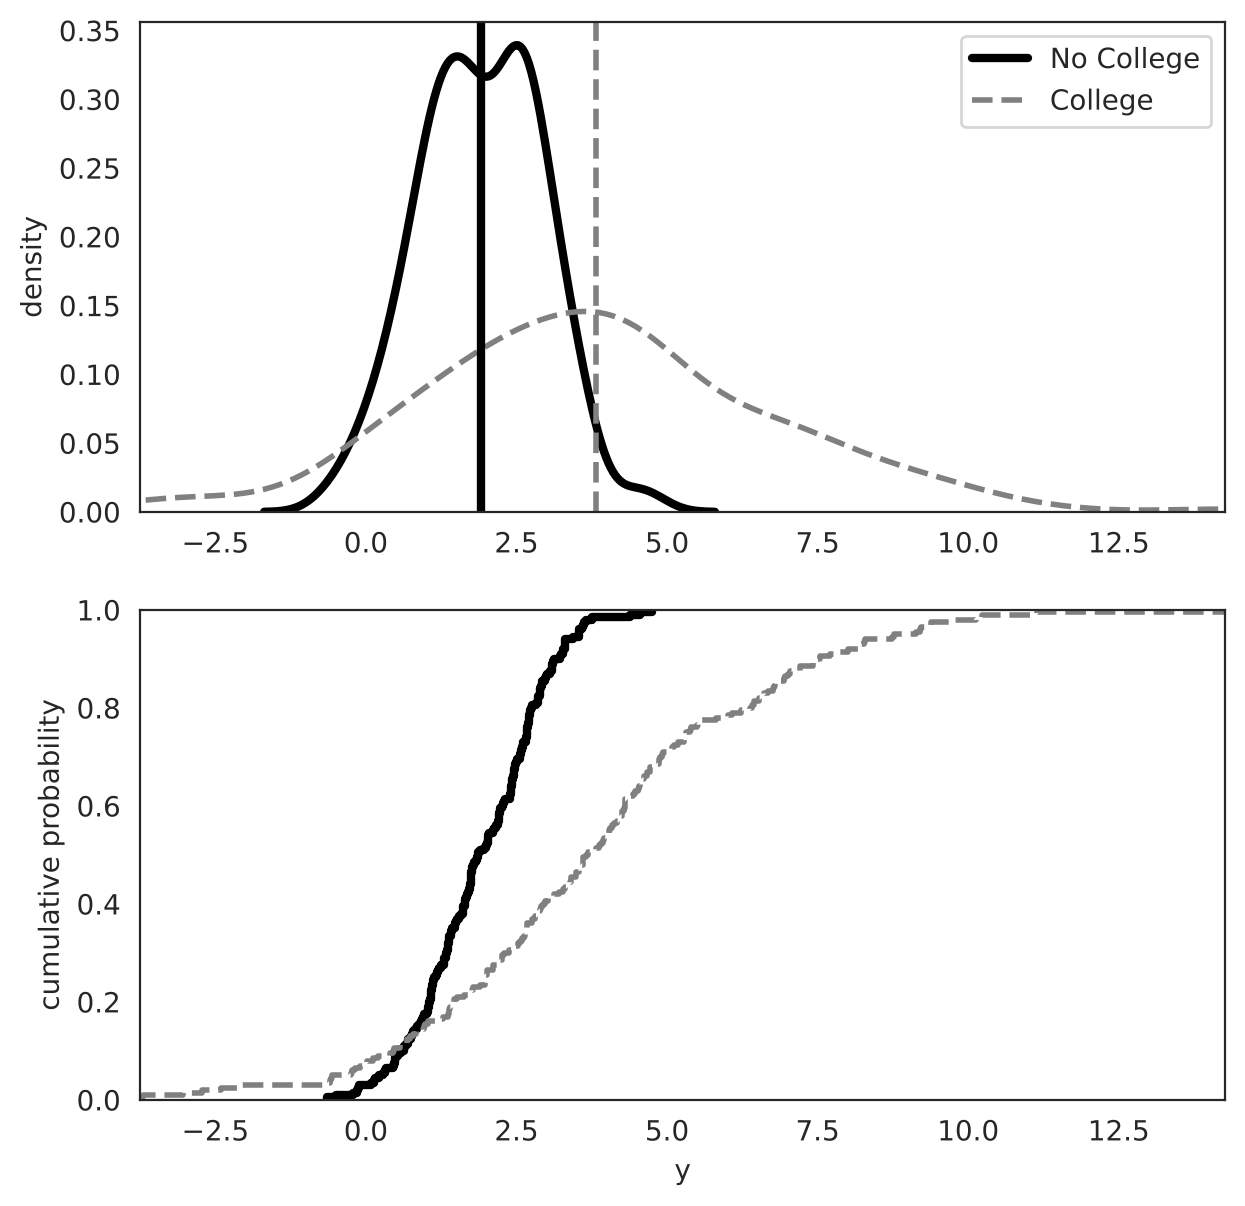

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking plotting style
sns.set_style('white')

plt.figure(figsize=(7, 7))

# creates a simple panel plot
# 2 rows, 1 column, and we draw in the first panel
plt.subplot(2, 1, 1)

# density of each potential outcome
# python starts counting at 0: y[:,0] is the first column (y[,1] in R)
sns.kdeplot(y[:,0], color='k', linewidth=3, label='No College')
sns.kdeplot(y[:,1], color='grey', linewidth=2, linestyle='--', label='College')

# vertical lines at the mean of each potential outcome
plt.axvline(np.mean(y[:,0]), color='k', linewidth=3)
plt.axvline(np.mean(y[:,1]), color='grey', linewidth=2, linestyle='--')

plt.xlim(np.min(y), np.max(y))
plt.ylabel('density')
plt.legend()

# second panel
plt.subplot(2, 1, 2)

# ecdf empirical cumulative distribution function.
sns.ecdfplot(y[:,0], color='k', linewidth=3)
sns.ecdfplot(y[:,1], color='grey', linewidth=2, linestyle='--')

plt.xlim(np.min(y), np.max(y))
plt.xlabel('y')
plt.ylabel('cumulative probability')

plt.show()

## 4.2.3 Distribution of the Treatment Effect

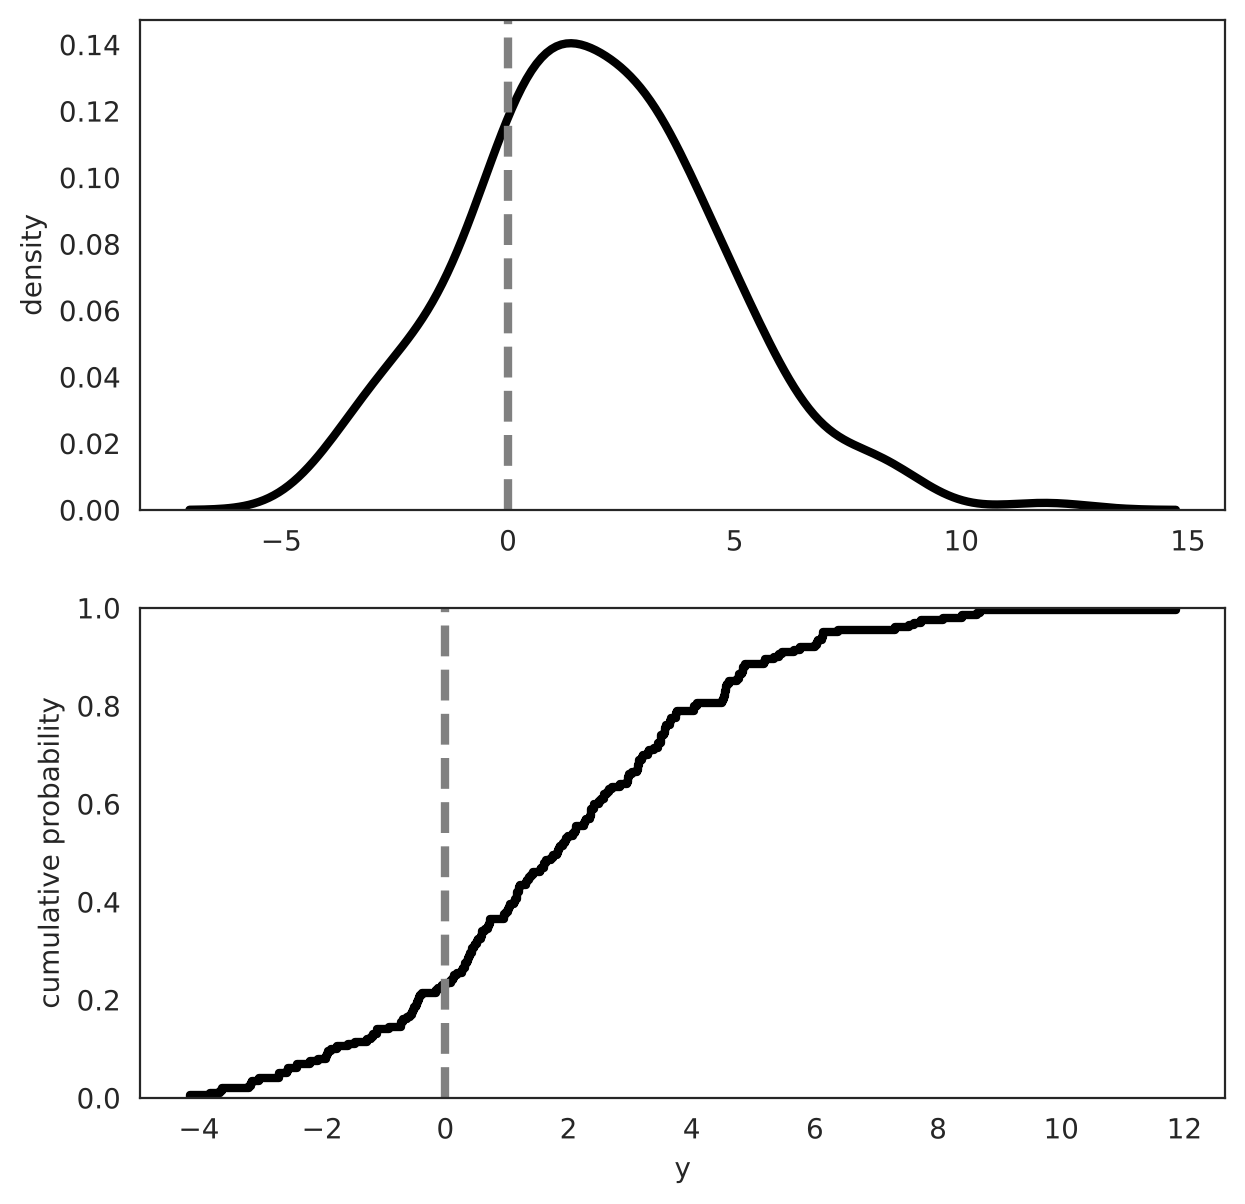

In [5]:
plt.figure(figsize=(7, 7))

# density of the treatment effect
# this is the difference between the two columns of y
plt.subplot(2, 1, 1)
sns.kdeplot(y[:,1] - y[:,0], color='k', linewidth=3)
# on the left of the dashed line, the treatment lowers the outcome
plt.axvline(0, color='grey', linestyle='--', linewidth=3)
plt.ylabel('density')

# and its cumulative distribution function
plt.subplot(2, 1, 2)
sns.ecdfplot(y[:,1] - y[:,0], color='k', linewidth=3)
plt.axvline(0, color='grey', linestyle='--', linewidth=3)
plt.xlabel('y')
plt.ylabel('cumulative probability')

plt.show()

## 4.3.1 ATE and Its Derivation

In [6]:
# mean of the difference vs difference of the means
print(np.mean(y[:,1] - y[:,0]))
print(np.mean(y[:,1]) - np.mean(y[:,0]))

1.901348660047539
1.9013486600475387


In [7]:
# in the book, R answers TRUE to the test with ==
# here the two numbers are not the same at the last decimal
# (the computer rounds the numbers), and == answers False
# np.isclose compares two numbers up to a very small difference
print(np.isclose(np.mean(y[:,1] - y[:,0]), np.mean(y[:,1]) - np.mean(y[:,0])))

True


## 4.3.4 ATE and Simulated Data

In [8]:
X = np.random.rand(N) < 0.3 # treatment assignment

# X is a vector of True/False, they count as 1/0 in the computation
Y = (1-X)*y[:,0] + X*y[:,1] # outcome conditional on treatment

In [9]:
# mean outcome of the treated minus mean outcome of the others
# the true average treatment effect is 2
print(np.mean(Y[X==1]) - np.mean(Y[X==0]))

2.017059653895333


## 4.4.2 Kolmogorov Bounds in Python

The book searches the largest difference between the two distributions with `optimize`. The difference is made of steps, so this search can stop before the true maximum, and then the bounds are too wide. Here we compute the difference on a grid of 1000 values and we take the largest one. For this reason the figure of 4.5.2 is not the same as in the book between 0 and 1.4.

In [10]:
def FL(b, y1, y0, K=1000):
    """
    Lower bound of the distribution of the treatment effect at the value b
    * y1 is the vector of outcomes with the treatment
    * y0 is the vector of outcomes without the treatment
    * K is the number of values of x where we compute the difference
    """
    # K values of x between the smallest and the largest outcome
    min_y = min(np.min(y1), np.min(y0))
    max_y = max(np.max(y1), np.max(y0))
    x_K = np.linspace(min_y, max_y, K)

    # difference between the two distributions at each value of x
    # the mean of a True/False vector is the share of True
    diff = []
    for x in x_K:
        diff.append(np.mean(y1 < x) - np.mean(y0 < x - b))

    # the lower bound is the largest difference, and it is at least 0
    return max(np.max(diff), 0)

def FU(b, y1, y0, K=1000):
    """
    Upper bound of the distribution of the treatment effect at the value b
    """
    min_y = min(np.min(y1), np.min(y0))
    max_y = max(np.max(y1), np.max(y0))
    x_K = np.linspace(min_y, max_y, K)

    diff = []
    for x in x_K:
        diff.append(np.mean(y1 < x) - np.mean(y0 < x - b))

    # the upper bound is 1 plus the smallest difference, and it is at most 1
    return 1 + min(np.min(diff), 0)

The book builds the grid of values on the range of y0 - y1, but the treatment effect is y1 - y0, so we build it on the range of y1 - y0 (if not, the lines stop before the right end of the distribution).

In [11]:
K = 50

# smallest and largest possible values of the treatment effect
min_diff = np.min(y[:,1]) - np.max(y[:,0])
max_diff = np.max(y[:,1]) - np.min(y[:,0])
del_diff = (max_diff - min_diff)/K

# K values between min_diff and max_diff
# np.arange(1, K+1) gives 1, 2, ..., K as c(1:K) in R
y_K = min_diff + np.arange(1, K+1)*del_diff

# the two bounds at each of the K values
# (sapply in R, a loop here)
lower = []
upper = []
for k in range(0, K):
    lower.append(FL(y_K[k], y[:,1], y[:,0]))
    upper.append(FU(y_K[k], y[:,1], y[:,0]))

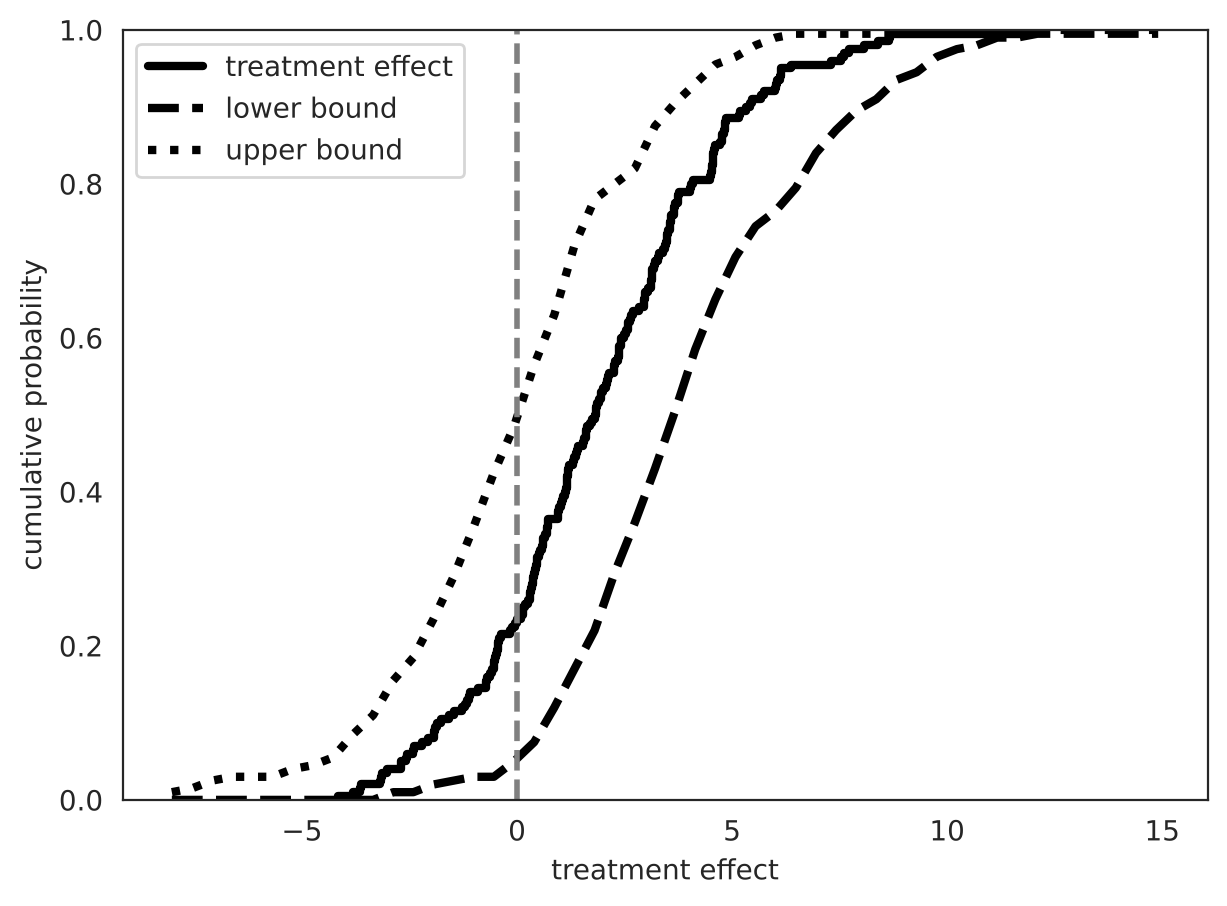

In [12]:
plt.figure(figsize=(7, 5))

# distribution of the treatment effect
# with normal data we cannot observe it
sns.ecdfplot(y[:,1] - y[:,0], color='k', linewidth=3, label='treatment effect')

# and its bounds, which use each column of y on its own
plt.plot(y_K, lower, color='k', linestyle='--', linewidth=3, label='lower bound')
plt.plot(y_K, upper, color='k', linestyle=':', linewidth=3, label='upper bound')

plt.axvline(0, color='grey', linestyle='--', linewidth=2)
plt.xlabel('treatment effect')
plt.ylabel('cumulative probability')
plt.legend()

plt.show()

In [13]:
# lower bound at 0
# it is above 0: some individuals must be harmed by the treatment
print(FL(0, y[:,1], y[:,0]))

0.05


## 4.5.1 Field Experiment Data

In [14]:
import pandas as pd

# this data set was saved with Stata version 13.
# R needs the package readstata13 for it, in Python pd.read_stata reads it
x = pd.read_stata('../data/seedanalysis_011204_080404.dta')

In [15]:
# Stata saved balchange with about 7 digits (type float) and pandas keeps this type
# R reads it with about 16 digits (type double)
# we do the same to get the same decimals as in the book
x['balchange'] = x['balchange'].astype(float)

# the sum of a row is NA when one of the three variables is missing
# (skipna=False to do as rowSums in R)
index_na = x[['treatment', 'balchange', 'marketing']].sum(axis=1, skipna=False).isna() == False
x1 = x[index_na]

# we are just going to look at the people who did not receive
# the marketing information.
# These people are split between those that received
# the account
# (treatment = 1), and those that did not (treatment = 0).
# balchange - measure their balance changed in a year.
bal_0 = x1[(x1['treatment']==0) & (x1['marketing']==0)]['balchange']
bal_1 = x1[(x1['treatment']==1) & (x1['marketing']==0)]['balchange']

# the distribution of balances is very skewed.
# so we take the log. the smallest value of balchange is -2168.88,
# with 2169 added all the values are positive
lbal_0 = np.log(bal_0 + 2169)
lbal_1 = np.log(bal_1 + 2169)

In [16]:
# number of people in each group
print(len(bal_0), len(bal_1))

469 842


In [17]:
# average treatment effect, in pesos
print(np.mean(bal_1) - np.mean(bal_0))

411.4664343127289


## 4.5.2 Bounds on the Distribution of Balance Changes

In [18]:
# the book shows this figure without its code
# we do as in 4.4.2, with the log balances of the two groups
K = 50
min_diff = np.min(lbal_1) - np.max(lbal_0)
max_diff = np.max(lbal_1) - np.min(lbal_0)
del_diff = (max_diff - min_diff)/K
y_K = min_diff + np.arange(1, K+1)*del_diff

lower = []
upper = []
for k in range(0, K):
    lower.append(FL(y_K[k], lbal_1, lbal_0))
    upper.append(FU(y_K[k], lbal_1, lbal_0))

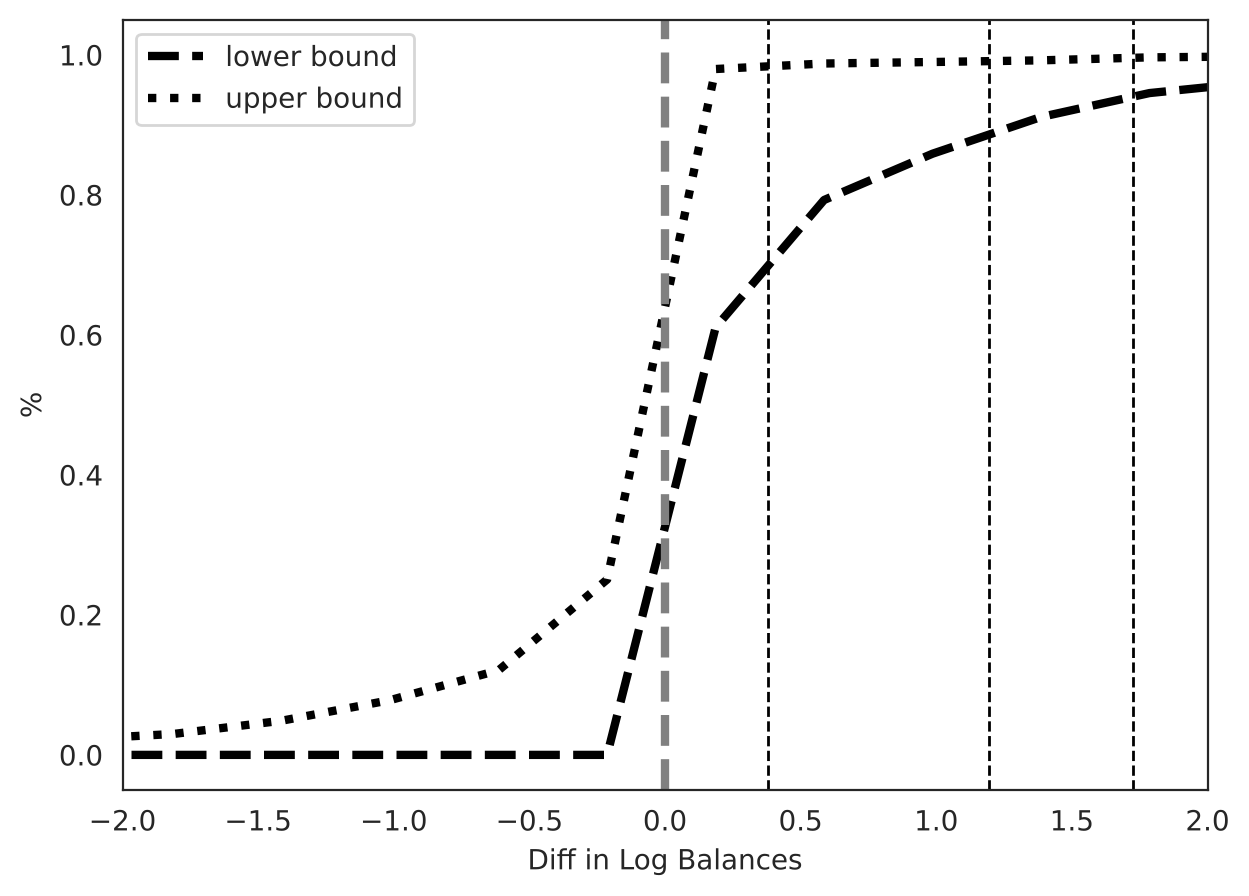

In [19]:
plt.figure(figsize=(7, 5))

plt.plot(y_K, lower, color='k', linestyle='--', linewidth=3, label='lower bound')
plt.plot(y_K, upper, color='k', linestyle=':', linewidth=3, label='upper bound')
plt.axvline(0, color='grey', linestyle='--', linewidth=3)

# marks at 1,000, 5,000 and 10,000 pesos
# (the log difference for a balance change which goes from 0 to this amount)
for pesos in [1000, 5000, 10000]:
    plt.axvline(np.log(pesos + 2169) - np.log(2169), color='k', linestyle='--', linewidth=1)

# same limits as in the book
plt.xlim(-2, 2)
plt.xlabel('Diff in Log Balances')
plt.ylabel('%')
plt.legend()

plt.show()

In [20]:
# lower bound at 0
# it is almost 0: we cannot show that some people save less with the account
# (in the figure the line goes up before 0 because it joins two points of the grid)
print(FL(0, lbal_1, lbal_0))

0.0006735916616442683


## 4.6.2 Simulation of Manski Bounds

In [21]:
c = 2
d = 4
f = -1

# creating a vector of 0s and 1s
Z = np.round(np.random.rand(N))
u_2 = np.random.normal(size=N)

# the hidden variable which decides the treatment
# it depends on u, which is also in the outcome y
xstar = f + c*u + d*Z + u_2

X = xstar > 0 # treatment assignment
Y = (1-X)*y[:,0] + X*y[:,1] # outcome conditional on treatment

# the true average treatment effect is 2
# this estimate is too high
print(np.mean(Y[X==1]) - np.mean(Y[X==0]))

2.7291067602322467


## 4.6.5 Natural Bounds with Simulated Data

In [22]:
# share of treated and of not treated
PX1 = np.mean(X==1)
PX0 = np.mean(X==0)

# mean outcome of each group
EY_X1 = np.mean(Y[X==1])
EY_X0 = np.mean(Y[X==0])

# smallest and largest outcomes in the data
minY = np.min(Y)
maxY = np.max(Y)

In [23]:
# ATE upper bound
print((EY_X1 - minY)*PX1 + (maxY - EY_X0)*PX0)

8.057358332796579


In [24]:
# ATE lower bound
print((EY_X1 - maxY)*PX1 + (minY - EY_X0)*PX0)

-5.810670125612562


## 4.6.8 Exogenous Variation in Simulated Data

In [25]:
# mean outcome for each value of X and of Z
# in Python the "and" of two conditions is &, with each condition in brackets
EY_X1Z1 = np.mean(Y[(X==1) & (Z==1)])
EY_X1Z0 = np.mean(Y[(X==1) & (Z==0)])
EY_X0Z1 = np.mean(Y[(X==0) & (Z==1)])
EY_X0Z0 = np.mean(Y[(X==0) & (Z==0)])

# share of treated and of not treated for each value of Z
PX1_Z1 = np.mean(X[Z==1]==1)
PX1_Z0 = np.mean(X[Z==0]==1)
PX0_Z1 = np.mean(X[Z==1]==0)
PX0_Z0 = np.mean(X[Z==0]==0)

In [26]:
# ATE upper bound
# the smallest of the two upper bounds (Z = 1 and Z = 0)
print(min((EY_X1Z1 - minY)*PX1_Z1 + (maxY - EY_X0Z1)*PX0_Z1,
          (EY_X1Z0 - minY)*PX1_Z0 + (maxY - EY_X0Z0)*PX0_Z0))

7.041136589392281


In [27]:
# ATE lower bound
# the largest of the two lower bounds
print(max((EY_X1Z1 - maxY)*PX1_Z1 + (minY - EY_X0Z1)*PX0_Z1,
          (EY_X1Z0 - maxY)*PX1_Z0 + (minY - EY_X0Z0)*PX0_Z0))

-4.814571585047954


## 4.6.10 Bounds with Monotonicity in the Simulated Data

In [28]:
# ATE upper bound
print((maxY - EY_X0)*PX0)

4.118572746790495


In [29]:
# ATE lower bound
print((EY_X1 - maxY)*PX1)

-4.104670919871218


## 4.7.1 Crime Data

In [30]:
# the data is standard Stata format
# R needs the library foreign to import it, in Python pd.read_stata does it
x = pd.read_stata('../data/UpdatedStateLevelData-2010.dta')

In [31]:
# as for balchange above, we convert the two variables that we average
# to get the same decimals as in the book
x['rataga'] = x['rataga'].astype(float)
x['area'] = x['area'].astype(float)

# the names of the states, in alphabetical order
states = sorted(x['state'].unique())

# the loop will create variables by adding to the lists
X = []
Y = []
Z = []

# len measures the number of elements in the object.
# note the first state is an empty name (3 rows with no data)
# so the loop starts at the second state
# this is position 1, python starts counting at 0 and not at 1 like R
for i in range(1, len(states)):

    state = states[i]

    # all the rows of the state
    x_state = x[x['state']==state]
    # and the rows of the state after 1990
    x_post = x[(x['state']==state) & (x['year'] > 1990)]

    # determines if a state has an RTC law at some point in time.
    # .sum() and .mean() ignore the NAs (na.rm = TRUE in R)
    X.append(x_state['shalll'].sum() > 0)

    # determines the average rate of aggrevated assualt for the
    # state post 1990.
    Y.append(x_post['rataga'].mean())

    # determines the physical area of the state
    # Small state = 0, large stage = 1
    Z.append(x_post['area'].mean() > 53960)

# we turn the lists into numpy arrays, to use them as the vectors of R
X = np.array(X)
Y = np.array(Y)
Z = np.array(Z)

In [32]:
# number of states, of states with an RTC law and of large states
print(len(Y), np.sum(X), np.sum(Z))

51 39 26


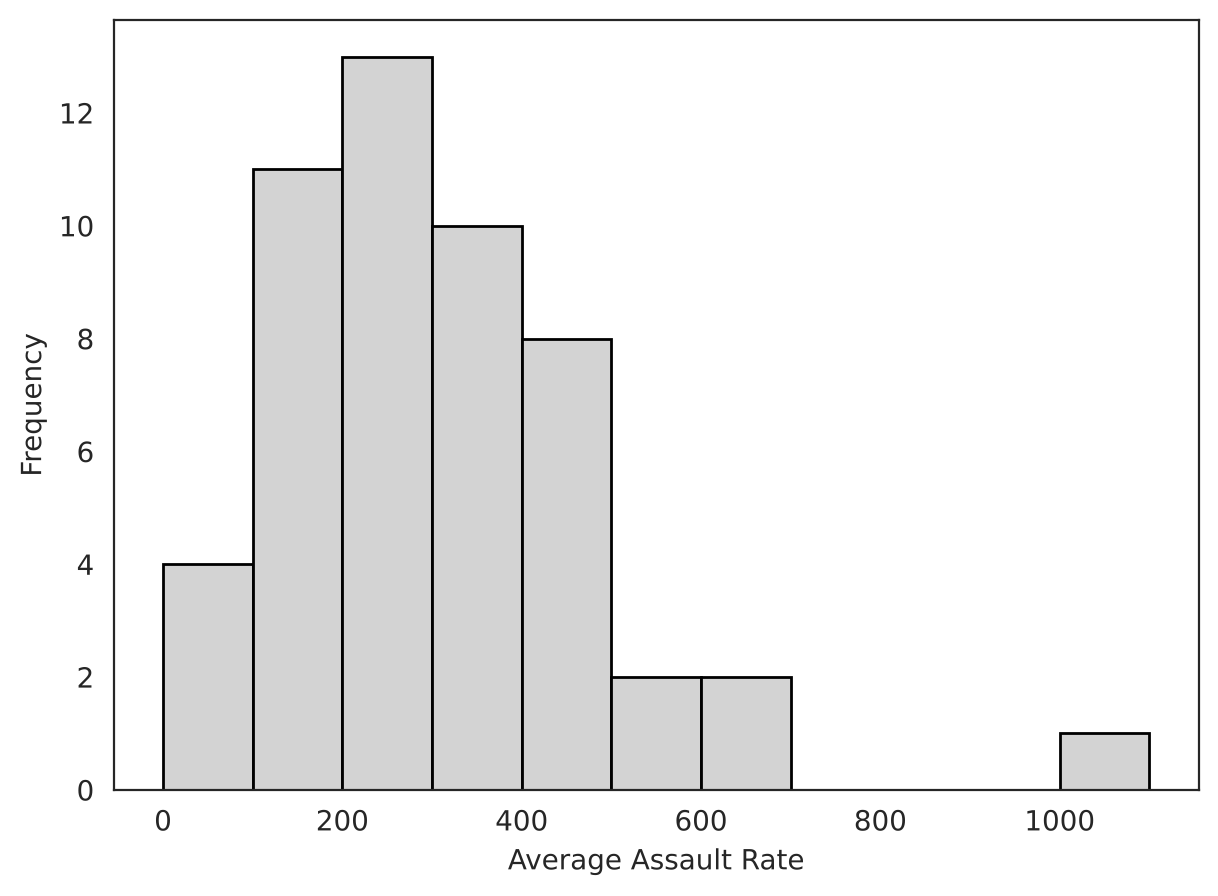

In [33]:
# histogram of the average aggravated assault rate per state
# one bar for each 100, as in the figure of the book
plt.figure(figsize=(7, 5))
plt.hist(Y, bins=np.arange(0, 1200, 100), color='lightgrey', edgecolor='k')
plt.xlabel('Average Assault Rate')
plt.ylabel('Frequency')
plt.show()

## 4.7.2 ATE of RTC Laws under Unconfoundedness

In [34]:
EY_X1 = np.mean(Y[X==1])
EY_X0 = np.mean(Y[X==0])
print(EY_X1 - EY_X0)

-80.65852427590488


## 4.7.3 Natural Bounds on ATE of RTC Laws

In [35]:
PX0 = np.mean(X==0)
PX1 = np.mean(X==1)

# the assault rate is per 100,000 people, so it lies between 0 and 100,000
minY = 0
maxY = 100000

# ATE upper bound
print((EY_X1 - minY)*PX1 + (maxY - EY_X0)*PX0)

23666.01125290814


In [36]:
# ATE lower bound
print((EY_X1 - maxY)*PX1 + (minY - EY_X0)*PX0)

-76333.98874709186


In [37]:
# tighter bounds with the smallest and the largest rates in the data
minY = np.min(Y)
maxY = np.max(Y)

# ATE upper bound
print((EY_X1 - minY)*PX1 + (maxY - EY_X0)*PX0)

334.1968751399162


In [38]:
# ATE lower bound
print((EY_X1 - maxY)*PX1 + (minY - EY_X0)*PX0)

-624.7654699833748


## 4.7.4 Bounds on ATE of RTC Laws with Exogenous Variation

In [39]:
# Z is the physical size of the state (1 for a large state)
PX1_Z1 = np.mean(X[Z==1]==1)
PX1_Z0 = np.mean(X[Z==0]==1)
PX0_Z1 = np.mean(X[Z==1]==0)
PX0_Z0 = np.mean(X[Z==0]==0)
EY_X1Z1 = np.mean(Y[(X==1) & (Z==1)])
EY_X1Z0 = np.mean(Y[(X==1) & (Z==0)])
EY_X0Z1 = np.mean(Y[(X==0) & (Z==1)])
EY_X0Z0 = np.mean(Y[(X==0) & (Z==0)])

# ATE upper bound
print(min((EY_X1Z1 - minY)*PX1_Z1 + (maxY - EY_X0Z1)*PX0_Z1,
          (EY_X1Z0 - minY)*PX1_Z0 + (maxY - EY_X0Z0)*PX0_Z0))

323.25041380834796


In [40]:
# ATE lower bound
print(max((EY_X1Z1 - maxY)*PX1_Z1 + (minY - EY_X0Z1)*PX0_Z1,
          (EY_X1Z0 - maxY)*PX1_Z0 + (minY - EY_X0Z0)*PX0_Z0))

-613.3811501985439


## 4.7.5 Bounds on ATE of RTC Laws with Monotonicity

In [41]:
# ATE upper bound
print((EY_X1 - minY)*PX1)

184.22033151540788


In [42]:
# ATE lower bound
print((minY - EY_X0)*PX0)

-75.66165522803074
